# Relevancia de la cláusula — ¿cuánto depende del damping?

El orden «by relevance» del Clause Analyzer sale de un PageRank personalizado entre cláusulas
([`docs/metricas/importancia-clausula.md`](../docs/metricas/importancia-clausula.md)). Su único
parámetro libre es el damping $d$: la probabilidad de seguir una flecha en vez de volver a
empezar. Hoy vale 0.5 (`RELEVANCE_DAMPING`). Este cuaderno repite el cálculo con $d$ de 0.01 a
0.99 y mira qué cambia.

Llama al módulo que ejecuta el servidor,
`server/services/graph/knowledge/personalized_pagerank.py`. Solo cambia `RELEVANCE_DAMPING` y el
tope de rondas mientras dura cada cálculo, y los devuelve a su valor.

Las cifras son del contrato entero, con todas sus partes, como la tabla del apartado 6 del
documento.

| Término | Significado |
|---|---|
| base | Lo que vale una fila que ninguna cláusula necesita. La relevancia se da en «veces la base». |
| fila que sube | Una fila que vale más que la base: alguna cláusula la necesita. |
| grupo mutuo | Cláusulas que se necesitan entre sí, directamente o en cadena: A necesita a B y B necesita a A. |
| $d/(1-d)$ | Cuántas flechas sigue el paseo, de media, antes de volver a empezar: 1 con $d=0.5$ y 5.7 con $d=0.85$. |

Se ejecuta con el entorno de `server/` (usa `networkx` y `scipy`, que ya están en sus
dependencias). Los gráficos son SVG hechos a mano, sin librerías nuevas.

In [1]:
import copy
import json
import math
import sys
from contextlib import contextmanager
from pathlib import Path

import networkx as nx
from IPython.display import SVG, display
from scipy.stats import spearmanr

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / 'infra').is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'server'))
from services.graph.knowledge import personalized_pagerank as ppr

TODAY = ppr.RELEVANCE_DAMPING
GRID = [round(0.01 * i, 2) for i in range(1, 100)]
SHOWN = [0.05, 0.15, 0.3, 0.5, 0.65, 0.75, 0.85, 0.95]
# Con d = 0.99 el paseo necesita unas 2 100 rondas para llegar a la tolerancia (apartado 6).
ROUNDS = 20_000

NAMES = {
    'BELLICUM': 'Bellicum', 'CARTAO': 'Santander', 'CONTRATO_AREQUIPA': 'Arequipa', 'SteelVault': 'SteelVault',
    'Synthetic_Halverson': 'HalversonCorvin', 'Synthetic_Orvane': 'OrvaneTalvera',
}


@contextmanager
def walking(damping, rounds):
    saved = ppr.RELEVANCE_DAMPING, ppr.MAX_ITERATIONS
    ppr.RELEVANCE_DAMPING, ppr.MAX_ITERATIONS = damping, rounds
    try:
        yield
    finally:
        ppr.RELEVANCE_DAMPING, ppr.MAX_ITERATIONS = saved


def relevance(kg, damping, rounds=ROUNDS):
    """La relevancia de cada fila con ese damping, tal como la devuelve el módulo."""
    with walking(damping, rounds):
        return ppr.compute(kg).by_clause


class Contract:
    def __init__(self, path):
        stem = path.stem.removeprefix('root_')
        self.name = next((short for prefix, short in NAMES.items() if stem.startswith(prefix)), stem)
        self.kg = json.loads(path.read_text(encoding='utf-8'))
        self.ref = {clause['id']: clause.get('ref') or clause['id'] for clause in self.kg['clauses']}
        today = ppr.compute(self.kg)
        self.rows = list(today.by_clause)
        self.links = ppr.needs(self.kg)
        # Las filas que suben son las que alguna cláusula necesita; cuántas, es lo que enseña «Needed by».
        self.readers = {clause: len({need.reader for need in needs}) for clause, needs in today.needed_by.items()}
        self.rising = [clause for clause in self.rows if clause in self.readers]
        graph = nx.DiGraph((link.reader, link.needed) for link in self.links)
        self.groups = [group for group in nx.strongly_connected_components(graph) if len(group) > 1]
        self.mutual = {clause for group in self.groups for clause in group}
        # Cuántas flechas salen de cada cláusula: entre cuántas reparte lo suyo.
        self.out = {clause: sum(link.reader == clause for link in self.links) for clause in self.rows}
        self.by_damping = {d: relevance(self.kg, d) for d in GRID}

    def times_base(self, d):
        values = self.by_damping[d]
        base = min(values.values())
        return {clause: round(values[clause] / base, 9) for clause in self.rows}

    def order(self, d):
        """Las filas que suben, de más a menos relevante; los empates, en el orden del contrato."""
        times = self.times_base(d)
        return sorted(self.rising, key=lambda clause: (-times[clause], self.rows.index(clause)))

    def label(self, clause):
        return '§' + self.ref[clause]


contracts = [Contract(path) for path in sorted((ROOT / 'infra' / 'json' / 'kg').glob('root_*.json'))]

print(f"{'contrato':19} {'filas':>5} {'flechas':>8} {'suben':>6} {'grupos mutuos':>14} {'filas en ellos':>15}")
for c in contracts:
    print(f'{c.name:19} {len(c.rows):>5} {len(c.links):>8} {len(c.rising):>6} {len(c.groups):>14} {len(c.mutual & set(c.rows)):>15}')

print('\nLos grupos mutuos:')
for c in contracts:
    for group in sorted(c.groups, key=lambda group: min(c.rows.index(x) if x in c.rows else len(c.rows) for x in group)):
        members = sorted(group, key=lambda x: [clause['id'] for clause in c.kg['clauses']].index(x))
        print(f'  {c.name:19} ' + ' ↔ '.join(c.label(x) for x in members))

contrato            filas  flechas  suben  grupos mutuos  filas en ellos
Bellicum               91      273     59             10              36
Santander              83       83     25              3               6
Arequipa               14        3      3              0               0
SteelVault             22        6      1              0               0
HalversonCorvin        19        7      4              2               4
OrvaneTalvera          48       29     20              3               8
lease_contract_10      20        8      4              1               2
lease_contract_166      9        0      0              0               0
lease_contract_201      8        7      3              0               0

Los grupos mutuos:
  Bellicum            §1.1 ↔ §1.4
  Bellicum            §2.3 ↔ §4.1 ↔ §4.2 ↔ §4.3 ↔ §4.4 ↔ §4.5 ↔ §4.6 ↔ §4.7 ↔ §4.8 ↔ §4.9 ↔ §4.10
  Bellicum            §5.1 ↔ §5.2 ↔ §5.3 ↔ §5.4 ↔ §5.5 ↔ §5.6 ↔ §6.2
  Bellicum            §7.2 ↔ §7.3
  Bellicum     

## 1. Lo que $d$ no puede cambiar

Qué filas suben lo decide el grafo, no $d$: una fila sube si alguna cláusula la necesita. $d$
solo puede cambiar el orden **entre** las filas que suben. Las demás empatan en la base con
cualquier valor.

In [2]:
for c in contracts:
    for d in GRID:
        times = c.times_base(d)
        assert {clause for clause in c.rows if times[clause] > 1 + 1e-6} == set(c.rising), (c.name, d)
    print(f'{c.name:19} suben las mismas {len(c.rising):>2} filas con los {len(GRID)} valores de d')

fixed = [c.name for c in contracts if len({tuple(c.order(d)) for d in GRID}) == 1]
print('\nContratos donde el orden completo es el mismo con cualquier d:', ', '.join(fixed))

Bellicum            suben las mismas 59 filas con los 99 valores de d
Santander           suben las mismas 25 filas con los 99 valores de d
Arequipa            suben las mismas  3 filas con los 99 valores de d
SteelVault          suben las mismas  1 filas con los 99 valores de d
HalversonCorvin     suben las mismas  4 filas con los 99 valores de d
OrvaneTalvera       suben las mismas 20 filas con los 99 valores de d
lease_contract_10   suben las mismas  4 filas con los 99 valores de d
lease_contract_166  suben las mismas  0 filas con los 99 valores de d
lease_contract_201  suben las mismas  3 filas con los 99 valores de d

Contratos donde el orden completo es el mismo con cualquier d: Arequipa, SteelVault, HalversonCorvin, lease_contract_10, lease_contract_166, lease_contract_201


## 2. Cuánto se mueve el orden frente a $d = 0.5$

Solo entre las filas que suben. ρ es la correlación de Spearman con el orden de hoy: 1 es el
mismo orden. La segunda tabla cuenta cuántas de las cinco primeras filas de hoy siguen entre las
cinco primeras (o de las que haya, si suben menos de cinco). «—»: las filas que suben empatan
entre sí y no hay orden que comparar.

In [3]:
def rho(c, d, other):
    a, b = c.times_base(d), other
    xs, ys = [a[clause] for clause in c.rising], [b[clause] for clause in c.rising]
    if len(set(xs)) < 2 or len(set(ys)) < 2:
        return None
    return spearmanr(xs, ys).statistic


def cell(value, form='{:.2f}'):
    return f"{'—' if value is None else form.format(value):>6}"


movable = [c for c in contracts if len(c.rising) >= 2]
header = f"{'':19}" + ''.join(f'{d:>6.2f}' for d in SHOWN)
print('ρ con el orden de d = 0.5\n' + header)
for c in movable:
    print(f'{c.name:19}' + ''.join(cell(rho(c, d, c.times_base(TODAY))) for d in SHOWN))

print('\nCuántas de las primeras filas de hoy siguen entre las primeras\n' + header)
for c in movable:
    k = min(5, len(c.rising))
    today = set(c.order(TODAY)[:k])
    print(f'{c.name:19}' + ''.join(cell(len(today & set(c.order(d)[:k])), '{}') for d in SHOWN) + f'   de {k}')

ρ con el orden de d = 0.5
                     0.05  0.15  0.30  0.50  0.65  0.75  0.85  0.95
Bellicum             0.95  0.96  0.99  1.00  0.99  0.97  0.94  0.89
Santander            0.99  1.00  1.00  1.00  1.00  1.00  0.99  0.99
Arequipa                —     —     —     —     —     —     —     —
HalversonCorvin      1.00  1.00  1.00  1.00  1.00  1.00  1.00  1.00
OrvaneTalvera        0.92  0.92  0.92  1.00  0.98  0.98  0.96  0.94
lease_contract_10    1.00  1.00  1.00  1.00  1.00  1.00  1.00  1.00
lease_contract_201   1.00  1.00  1.00  1.00  1.00  1.00  1.00  1.00

Cuántas de las primeras filas de hoy siguen entre las primeras
                     0.05  0.15  0.30  0.50  0.65  0.75  0.85  0.95
Bellicum                4     4     5     5     4     4     3     1   de 5
Santander               4     4     5     5     5     5     4     4   de 5
Arequipa                3     3     3     3     3     3     3     3   de 3
HalversonCorvin         4     4     4     4     4     4     4     4   de 

## 3. Dónde cambia: los tramos de $d$

Para cada contrato, los tramos de $d$ en los que las tres primeras filas son las mismas y están
en el mismo orden. Un contrato con un solo tramo no depende de $d$ en lo que el lector ve
primero.

In [4]:
first_change = {}
for c in movable:
    spans, start = [], GRID[0]
    for before, d in zip(GRID, GRID[1:]):
        if c.order(before)[:3] != c.order(d)[:3]:
            spans.append((start, before))
            start = d
    spans.append((start, GRID[-1]))
    changes = [d for before, d in zip(GRID, GRID[1:]) if c.order(before)[0] != c.order(d)[0]]
    first_change[c.name] = changes[0] if changes else None
    print(f'{c.name}: la primera fila ' + (f'cambia en d = {changes[0]:.2f}' if changes else 'es la misma con cualquier d'))
    for low, high in spans:
        print(f'    d de {low:.2f} a {high:.2f}   ' + ', '.join(c.label(x) for x in c.order(low)[:3]))

lowest = min(d for d in first_change.values() if d is not None)
print(f'\nLa primera fila es la misma en todos los contratos mientras d < {lowest:.2f}.')

Bellicum: la primera fila es la misma con cualquier d
    d de 0.01 a 0.73   §4.10, §3.2, §7.7
    d de 0.74 a 0.80   §4.10, §3.2, §6.5
    d de 0.81 a 0.82   §4.10, §3.2, §4.9
    d de 0.83 a 0.85   §4.10, §4.9, §3.2
    d de 0.86 a 0.94   §4.10, §4.9, §9.1
    d de 0.95 a 0.95   §4.10, §9.1, §4.9
    d de 0.96 a 0.99   §4.10, §9.1, §9.2
Santander: la primera fila cambia en d = 0.80
    d de 0.01 a 0.06   §18.8, §8.1, §6.1
    d de 0.07 a 0.79   §18.8, §6.1, §6.3
    d de 0.80 a 0.99   §6.1, §6.3, §18.8
Arequipa: la primera fila es la misma con cualquier d
    d de 0.01 a 0.99   §10, §11, §14
HalversonCorvin: la primera fila es la misma con cualquier d
    d de 0.01 a 0.99   §9, §8.2, §7.1


OrvaneTalvera: la primera fila cambia en d = 0.61
    d de 0.01 a 0.60   §11.2, §2.2, §8.4
    d de 0.61 a 0.99   §2.2, §8.4, §9.1
lease_contract_10: la primera fila es la misma con cualquier d
    d de 0.01 a 0.99   §13.1, §5, §13.2
lease_contract_201: la primera fila es la misma con cualquier d
    d de 0.01 a 0.99   §7, §2, §4

La primera fila es la misma en todos los contratos mientras d < 0.61.


## 4. Por qué cambia: los grupos mutuos

Cuando dos cláusulas se necesitan la una a la otra, el paseo va y vuelve entre ellas. Cuanto
más alto es $d$, más rondas aguanta sin volver a empezar, y más relevancia se queda dentro del
grupo. El gráfico mide eso: qué parte de la relevancia de todas las filas está en filas de un
grupo mutuo.

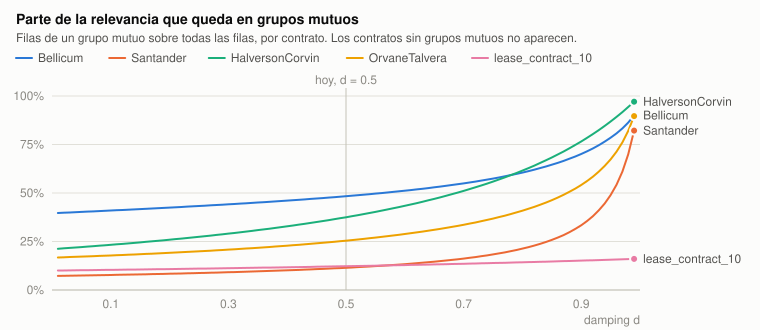

                     0.05  0.15  0.30  0.50  0.65  0.75  0.85  0.95
Bellicum              40%   42%   44%   48%   53%   57%   65%   78%
Santander              7%    8%    9%   11%   15%   18%   26%   49%
HalversonCorvin       22%   25%   29%   37%   47%   56%   68%   87%
OrvaneTalvera         17%   18%   21%   25%   31%   37%   46%   67%
lease_contract_10     10%   11%   11%   12%   13%   14%   15%   16%


In [5]:
INK, INK_SOFT, MUTED, GRIDLINE, AXIS, SURFACE = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#fcfcfb'
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4'
FONT = 'system-ui, -apple-system, Segoe UI, Helvetica, Arial, sans-serif'


def line_chart(title, subtitle, series, *, low, high, ticks, tick_label, legend, flip=False, right=120, height=330):
    """Líneas sobre d. `series` es una lista de (nombre, color, [(d, valor), ...])."""
    width, left, top, bottom = 760, 52, 96, 40
    plot_w, plot_h = width - left - right, height - top - bottom

    def x(d):
        return left + d * plot_w

    def y(value):
        share = (value - low) / (high - low)
        return top + (share if flip else 1 - share) * plot_h

    out = [f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" width="{width}" height="{height}" font-family="{FONT}" font-size="12">',
           f'<rect width="{width}" height="{height}" fill="{SURFACE}"/>',
           f'<text x="16" y="24" font-size="14" font-weight="600" fill="{INK}">{title}</text>',
           f'<text x="16" y="42" fill="{INK_SOFT}">{subtitle}</text>']
    at = 16
    for name, color in legend:
        out.append(f'<line x1="{at}" x2="{at + 16}" y1="58" y2="58" stroke="{color}" stroke-width="2" stroke-linecap="round"/>')
        out.append(f'<text x="{at + 22}" y="62" fill="{INK_SOFT}">{name}</text>')
        at += 22 + 6.4 * len(name) + 20
    for tick in ticks:
        out.append(f'<line x1="{left}" x2="{left + plot_w}" y1="{y(tick):.1f}" y2="{y(tick):.1f}" stroke="{GRIDLINE}" stroke-width="1"/>')
        out.append(f'<text x="{left - 8}" y="{y(tick) + 4:.1f}" text-anchor="end" fill="{MUTED}">{tick_label(tick)}</text>')
    out.append(f'<line x1="{x(TODAY):.1f}" x2="{x(TODAY):.1f}" y1="{top - 8}" y2="{top + plot_h}" stroke="{AXIS}" stroke-width="1"/>')
    out.append(f'<text x="{x(TODAY):.1f}" y="{top - 12}" text-anchor="middle" fill="{MUTED}">hoy, d = {TODAY}</text>')
    out.append(f'<line x1="{left}" x2="{left + plot_w}" y1="{top + plot_h}" y2="{top + plot_h}" stroke="{AXIS}" stroke-width="1"/>')
    for tick in (0.1, 0.3, 0.5, 0.7, 0.9):
        out.append(f'<text x="{x(tick):.1f}" y="{top + plot_h + 18}" text-anchor="middle" fill="{MUTED}">{tick}</text>')
    out.append(f'<text x="{left + plot_w}" y="{height - 6}" text-anchor="end" fill="{MUTED}">damping d</text>')
    for _, color, points in series:
        path = ' '.join(f"{'M' if i == 0 else 'L'}{x(d):.1f},{y(value):.1f}" for i, (d, value) in enumerate(points))
        out.append(f'<path d="{path}" fill="none" stroke="{color}" stroke-width="2" stroke-linejoin="round" stroke-linecap="round"/>')
    taken = []
    for name, color, points in series:
        d, value = points[-1]
        out.append(f'<circle cx="{x(d):.1f}" cy="{y(value):.1f}" r="4" fill="{color}" stroke="{SURFACE}" stroke-width="2"/>')
        # Una etiqueta que pisaría a otra no se pone: queda la leyenda y la tabla de debajo.
        if all(abs(y(value) - other) >= 13 for other in taken):
            taken.append(y(value))
            out.append(f'<text x="{x(d) + 9:.1f}" y="{y(value) + 4:.1f}" fill="{INK_SOFT}">{name}</text>')
    return SVG(''.join(out) + '</svg>')


def mutual_share(c, d):
    values = c.by_damping[d]
    return sum(values[clause] for clause in c.rows if clause in c.mutual) / sum(values.values())


with_groups = [c for c in contracts if c.mutual & set(c.rows)]
colors = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA]
display(line_chart(
    'Parte de la relevancia que queda en grupos mutuos',
    'Filas de un grupo mutuo sobre todas las filas, por contrato. Los contratos sin grupos mutuos no aparecen.',
    [(c.name, color, [(d, mutual_share(c, d)) for d in GRID]) for c, color in zip(with_groups, colors)],
    low=0, high=1, ticks=(0, 0.25, 0.5, 0.75, 1), tick_label=lambda t: f'{t:.0%}',
    legend=[(c.name, color) for c, color in zip(with_groups, colors)],
))

print(header)
for c in with_groups:
    print(f'{c.name:19}' + ''.join(f'{mutual_share(c, d):>6.0%}' for d in SHOWN))

Lo que eso hace con el orden, en los contratos donde las cinco primeras filas cambian. Cada
línea es una fila que llega a estar entre las cinco primeras con algún $d$; la altura es su
puesto entre las filas que suben. En la tabla, «la necesitan» es cuántas cláusulas la necesitan
y «necesita a» es cuántas flechas salen de ella: entre cuántas reparte lo suyo.

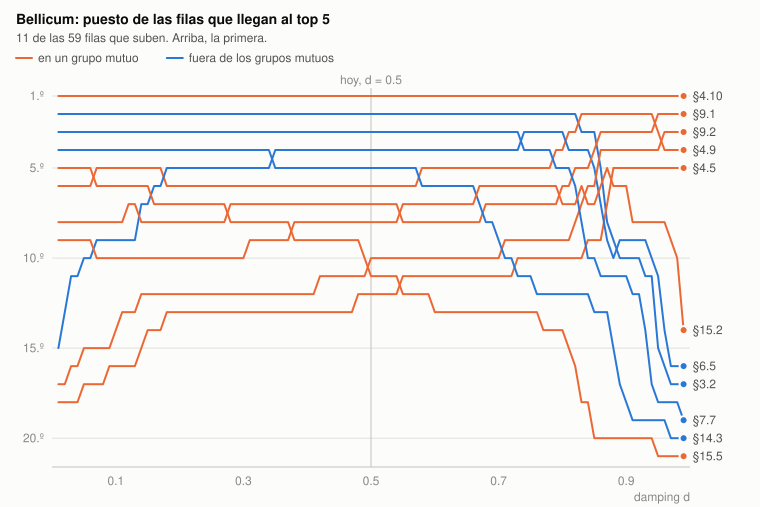

puesto con d =    0.05  0.15  0.30  0.50  0.65  0.75  0.85  0.95   grupo mutuo  la necesitan  necesita a
§4.10                1     1     1     1     1     1     1     1            sí            10           9
§3.2                 2     2     2     2     2     2     3    15            no            10           1
§7.7                 3     3     3     3     3     4    10    18            no             7           0
§6.5                10     7     5     4     4     3     5    11            no             1           0
§14.3                4     4     4     5     6    11    13    19            no             7           0
§4.9                 6     5     6     6     5     5     2     3            sí             5           3
§9.1                 8     8     7     7     8     7     4     2            sí             2           1
§15.2                9    10    10     8     7     6     7     8            sí             2           1
§9.2                15    12    12    10    10     9   

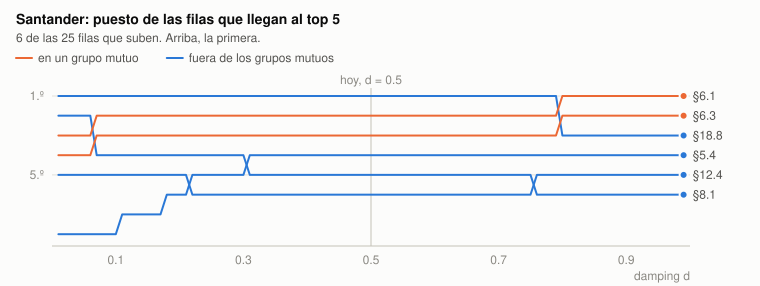

puesto con d =    0.05  0.15  0.30  0.50  0.65  0.75  0.85  0.95   grupo mutuo  la necesitan  necesita a
§18.8                1     1     1     1     1     1     3     3            no            12           0
§6.1                 3     2     2     2     2     2     1     1            sí             4           1
§6.3                 4     3     3     3     3     3     2     2            sí             4           1
§5.4                 8     7     5     4     4     4     4     4            no             3           0
§8.1                 2     4     4     5     5     5     6     6            no             3           1
§12.4                5     5     6     6     6     6     5     5            no             5           1



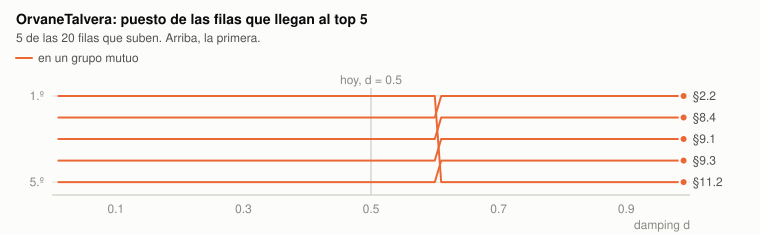

puesto con d =    0.05  0.15  0.30  0.50  0.65  0.75  0.85  0.95   grupo mutuo  la necesitan  necesita a
§11.2                1     1     1     1     5     5     5     5            sí             2           2
§2.2                 2     2     2     2     1     1     1     1            sí             1           2
§8.4                 3     3     3     3     2     2     2     2            sí             1           1
§9.1                 4     4     4     4     3     3     3     3            sí             1           1
§9.3                 5     5     5     5     4     4     4     4            sí             1           1



In [6]:
def rank_chart(c):
    ranks = {d: {clause: place for place, clause in enumerate(c.order(d), 1)} for d in GRID}
    shown = [clause for clause in c.rising if any(ranks[d][clause] <= 5 for d in GRID)]
    deepest = max(ranks[d][clause] for d in GRID for clause in shown)
    ticks = [t for t in (1, 5, 10, 15, 20, 25, 30) if t <= deepest]
    series = [(c.label(clause), ORANGE if clause in c.mutual else BLUE, [(d, ranks[d][clause]) for d in GRID]) for clause in shown]
    classes = [('en un grupo mutuo', ORANGE), ('fuera de los grupos mutuos', BLUE)]
    display(line_chart(
        f'{c.name}: puesto de las filas que llegan al top 5',
        f'{len(shown)} de las {len(c.rising)} filas que suben. Arriba, la primera.',
        series, low=1, high=max(deepest, 5) + 0.6, ticks=ticks, tick_label=lambda t: f'{t}.º', flip=True, right=70,
        height=150 + 17 * max(deepest, 5),
        legend=[(name, color) for name, color in classes if any(color == used for _, used, _ in series)],
    ))
    print(f"{'puesto con d =':16}" + ''.join(f'{d:>6.2f}' for d in SHOWN) + f"   {'grupo mutuo':>11} {'la necesitan':>13} {'necesita a':>11}")
    for clause in sorted(shown, key=lambda clause: ranks[TODAY][clause]):
        print(f'{c.label(clause):16}' + ''.join(f'{ranks[d][clause]:>6}' for d in SHOWN)
              + f"   {'sí' if clause in c.mutual else 'no':>11} {c.readers[clause]:>13} {c.out[clause]:>11}")
    print()


moving = [c for c in movable if len({tuple(c.order(d)[:5]) for d in GRID if d <= 0.95}) > 1]
for c in moving:
    rank_chart(c)

## 5. ¿Hay algo que elija $d$?

Dos referencias que no dependen del paseo:

- **«Needed by N».** Lo que la fila enseña en «Linked»: cuántas cláusulas la necesitan. ρ entre
  la relevancia y ese número, en las filas que suben. Dice cuánto del orden se puede comprobar
  contando en la propia fila.
- **Los enlaces del ground truth.** Solo en los dos contratos sintéticos. Se repite el paseo con
  las relaciones que `infra/ground_truth/*_1_grafo.txt` dice que el grafo debe tener, con el
  mismo $d$, y se compara con el orden que sale de la extracción: ρ sobre todas las filas, y
  cuántas de las cinco primeras coinciden.

Si alguna de las dos subiera o bajara con $d$, serviría para elegirlo.

In [7]:
print('ρ entre la relevancia y «Needed by N»\n' + header)
for c in movable:
    print(f'{c.name:19}' + ''.join(cell(rho(c, d, c.readers)) for d in SHOWN))

# «Relaciones entre secciones» de cada ground truth, como están escritas ahí: las del núcleo y,
# después, las opcionales. En Orvane, «14.1 activa 8.4» se toma como una remisión de 14.1 a 8.4.
GROUND_TRUTH = {
    'OrvaneTalvera': [
        ('modifies', '8.4', ['2.2']), ('modifies', '11.2', ['4.2', '10.1']), ('references', '9.3', ['9.1']),
        ('depends_on', '14.1', ['1.8']), ('references', '14.1', ['8.4']), ('references', '2.2', ['8.4']),
        ('references', '1.3', ['3.3']), ('references', '10.2', ['9.2']), ('references', '11.1', ['10', '12']),
        ('references', '13.5', ['4.4', '7.1', '10', '11', '12']),
    ],
    'HalversonCorvin': [
        ('modifies', '7.2', ['7.1']), ('modifies', '9', ['8.2']), ('references', '7.2', ['7.1']), ('references', '9', ['8.2']),
    ],
}


def with_truth(c):
    """El grafo del contrato con sus enlaces entre cláusulas cambiados por los del ground truth."""
    by_ref = {clause['ref']: clause['id'] for clause in c.kg['clauses'] if clause.get('ref')}
    kg = copy.deepcopy(c.kg)
    kg['edges'] = [edge for edge in kg['edges'] if edge['type'] not in ppr.RELATION_BY_EDGE]
    for kind, written_in, named in GROUND_TRUTH[c.name]:
        for number in named:
            # Un artículo que no es una cláusula del grafo vale por las cláusulas que cuelgan de él.
            targets = [by_ref[number]] if number in by_ref else [cid for ref, cid in by_ref.items() if ref.startswith(number + '.')]
            kg['edges'] += [{'source': by_ref[written_in], 'target': target, 'type': kind} for target in targets]
    return kg


def first(values, rows, k=5):
    return set(sorted(rows, key=lambda clause: (-round(values[clause], 12), rows.index(clause)))[:k])


print('\nContra el orden que dan los enlaces del ground truth\n' + header)
for c in contracts:
    if c.name not in GROUND_TRUTH:
        continue
    truth = with_truth(c)
    agreement, shared = [], []
    for d in SHOWN:
        ideal, ours = relevance(truth, d), c.by_damping[d]
        agreement.append(spearmanr([ours[r] for r in c.rows], [ideal[r] for r in c.rows]).statistic)
        shared.append(len(first(ours, c.rows) & first(ideal, c.rows)))
    print(f'{c.name:19}' + ''.join(cell(v) for v in agreement) + '   ρ')
    print(f"{'':19}" + ''.join(cell(v, '{}') for v in shared) + '   top 5 en común')

ρ entre la relevancia y «Needed by N»
                     0.05  0.15  0.30  0.50  0.65  0.75  0.85  0.95
Bellicum             0.60  0.59  0.61  0.62  0.63  0.60  0.58  0.56
Santander            0.80  0.81  0.81  0.81  0.81  0.81  0.80  0.80
Arequipa                —     —     —     —     —     —     —     —
HalversonCorvin      0.82  0.82  0.82  0.82  0.82  0.82  0.82  0.82
OrvaneTalvera        0.27  0.27  0.27  0.35  0.27  0.27  0.19  0.23
lease_contract_10    0.77  0.77  0.77  0.77  0.77  0.77  0.77  0.77
lease_contract_201   0.87  0.87  0.87  0.87  0.87  0.87  0.87  0.87

Contra el orden que dan los enlaces del ground truth
                     0.05  0.15  0.30  0.50  0.65  0.75  0.85  0.95


HalversonCorvin      0.99  0.99  0.99  0.99  0.99  0.99  0.99  0.99   ρ
                        5     5     5     5     5     5     5     5   top 5 en común


OrvaneTalvera        0.62  0.62  0.62  0.66  0.65  0.65  0.65  0.65   ρ
                        3     3     3     3     3     3     3     3   top 5 en común


## 6. El tope de 200 rondas

El módulo para a las 200 rondas aunque no haya llegado a la tolerancia de $10^{-9}$. El error
baja como $d^t$, así que hacen falta unas $\ln(10^{-9})/\ln d$ rondas. Con el $d$ de hoy sobran.
Esta celda compara el resultado con el tope del módulo y sin él.

In [8]:
print(f"{'d':>5} {'rondas que hacen falta':>23} {'mayor diferencia en una fila':>30} {'contratos con otro orden':>26}")
for d in (0.5, 0.85, 0.9, 0.95, 0.99):
    needed = math.ceil(math.log(ppr.TOLERANCE) / math.log(d))
    gap, reordered = 0.0, 0
    for c in contracts:
        capped, settled = relevance(c.kg, d, ppr.MAX_ITERATIONS), c.by_damping[d]
        gap = max(gap, max(abs(capped[r] - settled[r]) / settled[r] for r in c.rows))
        base = min(capped.values())
        times = {r: round(capped[r] / base, 9) for r in c.rows}
        reordered += sorted(c.rising, key=lambda r: (-times[r], c.rows.index(r))) != c.order(d)
    print(f'{d:>5} {needed:>23} {gap:>30.1e} {reordered:>26}')
print(f'\nTope del módulo: {ppr.MAX_ITERATIONS} rondas. Todo lo anterior se calculó sin ese tope.')

    d  rondas que hacen falta   mayor diferencia en una fila   contratos con otro orden


  0.5                      30                        0.0e+00                          0


 0.85                     128                        0.0e+00                          0


  0.9                     197                        0.0e+00                          0


 0.95                     405                        7.2e-06                          0


 0.99                    2062                        5.4e-02                          2

Tope del módulo: 200 rondas. Todo lo anterior se calculó sin ese tope.


## Lectura

Con los nueve grafos de `infra/json/kg` del 16 de noviembre de 2026:

- **$d$ no decide qué filas suben.** En los nueve contratos suben las mismas con cualquier valor.
- **En seis contratos $d$ no cambia nada.** Arequipa, SteelVault, HalversonCorvin y los tres
  arrendamientos tienen el mismo orden de 0.01 a 0.99.
- **En los otros tres, el orden de hoy aguanta en un tramo ancho.** Con $d$ entre 0.07 y 0.60,
  las tres primeras filas de los nueve contratos son las de hoy. En Bellicum aguantan hasta
  0.73. La primera fila no cambia en ningún contrato mientras $d < 0.61$.
- **Por encima de 0.6 mandan los grupos mutuos.** De $d = 0.5$ a $d = 0.85$, la parte de la
  relevancia que queda en ellos pasa del 48 % al 65 % en Bellicum, del 11 % al 26 % en Santander
  y del 25 % al 46 % en OrvaneTalvera. Las filas que muchas cláusulas necesitan, pero que no
  están en un grupo mutuo, pierden puestos: en Santander, §18.8 (la necesitan 12) deja de ser
  la primera con 0.80; en Bellicum, §3.2 (la necesitan 10) baja de 2.ª a 15.ª con 0.95.
- **Nada externo elige $d$.** El parecido con «Needed by N» y con el orden que dan los enlaces
  del ground truth casi no se mueve con $d$.
- **El tope de 200 rondas solo importa por encima de 0.9.** Con 0.99 cambia el orden en dos
  contratos.

En resumen: 0.5 está dentro del tramo donde el orden no depende de $d$. El experimento no da un
motivo para cambiarlo, y sí para no pasar de 0.6. No dice cuál es el orden correcto: para eso
sigue faltando un criterio externo.